# Bomberman AI — Notebook Benchmark Pathfinding

Notebook ini membandingkan performa lima algoritma pathfinding yang digunakan pada project **Bomberman AI Pathfinding**:
BFS, Dijkstra, UCS, GBFS, dan A\*.

## Fokus eksperimen
1. **Suite 1 — Efisiensi**: nodes explored, waktu eksekusi, dan panjang path pada dua jenis peta.
2. **Suite 2 — Anti-deadlock**: efektivitas history penalty dalam menekan siklus pada simulasi Bot-vs-Bot.
3. **Suite 3 — Skalabilitas**: pengaruh kepadatan dinding kayu terhadap performa algoritma.
4. **Suite 4 — Profiling jarak**: bagaimana nodes explored berubah seiring jarak Manhattan start–target.

> **Catatan**: Notebook ini berdiri sendiri dan tidak membutuhkan server FastAPI yang berjalan.
> Implementasi algoritma didefinisikan ulang di dalam notebook agar eksperimen dapat dijalankan mandiri.
> Karena itu, angka di sini adalah perbandingan **relatif antar algoritma**, bukan reproduksi persis metrik UI.

**Library dan visual**

In [ ]:
import time
import heapq
import random
import itertools
import copy
from collections import deque
from typing import List, Tuple, Dict, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

# ── Pengaturan tampilan ──────────────────────────────────────────────
sns.set_theme(style="darkgrid", palette="muted", font_scale=1.1)
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})

# Warna per algoritma (konsisten di semua grafik)
ALGO_COLORS = {
    "BFS":      "#4e9af1",
    "Dijkstra": "#f4a261",
    "UCS":      "#2a9d8f",
    "GBFS":     "#e76f51",
    "A*":       "#c77dff",
}
ALGO_ORDER = ["BFS", "Dijkstra", "UCS", "GBFS", "A*"]

print("✓ Import selesai.")

✓ Import selesai.


---
## Sel 2 — Skema nilai grid

| Nilai | Arti            | Biaya masuk |
|------:|:----------------|:-----------|
| `0`   | Lantai          | `1.0`       |
| `1`   | Dinding permanen| tidak bisa  |
| `2`   | Dinding kayu    | `6.0`       |
| `3`   | Bom aktif       | tidak bisa  |
| `4`   | Runtuh (SD)     | tidak bisa  |

Biaya kayu di notebook ini adalah **6.0** (sedikit berbeda dari server yang memakai 5.5) agar bilangan bulat dan lebih mudah dikontrol secara eksperimental.

**Definisi Peta Benchmark**

In [ ]:
ROWS, COLS = 13, 15

# ── MAP_OPEN: hanya dinding permanen, tanpa kayu ─────────────────────
MAP_OPEN = [
    [1,1,1,1,1,1,1,1,1,1,1,1,1,1,1],
    [1,0,0,0,0,0,0,0,0,0,0,0,0,0,1],
    [1,0,1,0,1,0,1,0,1,0,1,0,1,0,1],
    [1,0,0,0,0,0,0,0,0,0,0,0,0,0,1],
    [1,0,1,0,1,0,1,0,1,0,1,0,1,0,1],
    [1,0,0,0,0,0,0,0,0,0,0,0,0,0,1],
    [1,0,1,0,1,0,1,0,1,0,1,0,1,0,1],
    [1,0,0,0,0,0,0,0,0,0,0,0,0,0,1],
    [1,0,1,0,1,0,1,0,1,0,1,0,1,0,1],
    [1,0,0,0,0,0,0,0,0,0,0,0,0,0,1],
    [1,0,1,0,1,0,1,0,1,0,1,0,1,0,1],
    [1,0,0,0,0,0,0,0,0,0,0,0,0,0,1],
    [1,1,1,1,1,1,1,1,1,1,1,1,1,1,1],
]

# ── MAP_COMPLEX: banyak dinding kayu, mirip peta Klasik aplikasi ──────
MAP_COMPLEX = [
    [1,1,1,1,1,1,1,1,1,1,1,1,1,1,1],
    [1,0,0,2,2,2,2,2,2,2,2,2,0,0,1],
    [1,0,1,2,1,2,1,2,1,2,1,2,1,0,1],
    [1,2,2,2,2,2,2,2,2,2,2,2,2,2,1],
    [1,2,1,2,1,2,1,2,1,2,1,2,1,2,1],
    [1,2,2,2,2,0,2,2,2,2,2,2,2,2,1],
    [1,2,1,2,1,2,1,2,1,2,1,2,1,2,1],
    [1,2,2,2,2,2,2,2,2,0,2,2,2,2,1],
    [1,2,1,2,1,2,1,2,1,2,1,2,1,2,1],
    [1,2,2,2,2,2,2,2,2,2,2,2,2,2,1],
    [1,0,1,2,1,2,1,2,1,2,1,2,1,0,1],
    [1,0,0,2,2,2,2,2,2,2,2,2,0,0,1],
    [1,1,1,1,1,1,1,1,1,1,1,1,1,1,1],
]

# ── MAP_CORRIDOR: dinding kayu membentuk lorong vertikal ─────────────
MAP_CORRIDOR = [
    [1,1,1,1,1,1,1,1,1,1,1,1,1,1,1],
    [1,0,0,2,0,0,2,0,0,2,0,0,2,0,1],
    [1,0,1,0,1,0,1,0,1,0,1,0,1,0,1],
    [1,2,0,0,0,0,0,0,0,0,0,0,0,2,1],
    [1,0,1,0,1,0,1,0,1,0,1,0,1,0,1],
    [1,0,0,2,0,0,0,0,0,0,0,2,0,0,1],
    [1,0,1,0,1,0,1,0,1,0,1,0,1,0,1],
    [1,0,0,2,0,0,0,0,0,0,0,2,0,0,1],
    [1,0,1,0,1,0,1,0,1,0,1,0,1,0,1],
    [1,2,0,0,0,0,0,0,0,0,0,0,0,2,1],
    [1,0,1,0,1,0,1,0,1,0,1,0,1,0,1],
    [1,0,0,2,0,0,2,0,0,2,0,0,2,0,1],
    [1,1,1,1,1,1,1,1,1,1,1,1,1,1,1],
]

MAPS = {
    "MAP_OPEN":     MAP_OPEN,
    "MAP_COMPLEX":  MAP_COMPLEX,
    "MAP_CORRIDOR": MAP_CORRIDOR,
}

# Statistik grid
for name, g in MAPS.items():
    flat = [cell for row in g for cell in row]
    n_floor = flat.count(0)
    n_perm  = flat.count(1)
    n_wood  = flat.count(2)
    total   = len(flat)
    print(f"{name}: lantai={n_floor} ({n_floor/total*100:.1f}%), "
          f"permanen={n_perm} ({n_perm/total*100:.1f}%), "
          f"kayu={n_wood} ({n_wood/total*100:.1f}%)")

MAP_OPEN: lantai=113 (57.9%), permanen=82 (42.1%), kayu=0 (0.0%)
MAP_COMPLEX: lantai=14 (7.2%), permanen=82 (42.1%), kayu=99 (50.8%)
MAP_CORRIDOR: lantai=97 (49.7%), permanen=82 (42.1%), kayu=16 (8.2%)


**Implementasi patchfinding**

Implementasi di bawah ini berdiri sendiri dan konsisten dengan logika di main.py, dengan penyesuaian kecil yang didokumentasikan pada docs/algoritma.md § 9.

In [ ]:
# ── Konstanta biaya ───────────────────────────────────────────────────
WOOD_COST      = 6.0
HISTORY_PENALTY = 5.0   # per kunjungan (lebih sederhana dari server)
PASSABLE       = {0, 2}  # nilai grid yang bisa dilewati

DIRS4 = [(-1, 0), (1, 0), (0, -1), (0, 1)]


def manhattan(a: Tuple[int,int], b: Tuple[int,int]) -> int:
    return abs(a[0]-b[0]) + abs(a[1]-b[1])


def build_history_weights(history: List[Tuple[int,int]]) -> Dict[Tuple[int,int], float]:
    """Konversi list history posisi menjadi bobot penalti."""
    hw: Dict[Tuple[int,int], float] = {}
    for pos in history:
        hw[pos] = hw.get(pos, 0.0) + HISTORY_PENALTY
    return hw


def get_neighbors(cell, grid, hw={}):
    """Kembalikan daftar (neighbor, cost) dari cell yang diberikan."""
    r, c = cell
    result = []
    for dr, dc in DIRS4:
        nr, nc = r+dr, c+dc
        if 0 <= nr < ROWS and 0 <= nc < COLS:
            v = grid[nr][nc]
            if v not in PASSABLE:
                continue
            base = 1.0 if v == 0 else WOOD_COST
            cost = base + hw.get((nr, nc), 0.0)
            result.append(((nr, nc), cost))
    return result


def reconstruct(came_from, start, goal):
    if goal == start:
        return [start]
    if goal not in came_from:
        return []
    path, cur = [], goal
    while cur in came_from:
        path.append(cur)
        cur = came_from[cur]
    path.append(start)
    path.reverse()
    return path


# ── BFS ──────────────────────────────────────────────────────────────
def run_bfs(grid, start, target, history=None):
    hw = build_history_weights(history) if history else {}
    t0 = time.perf_counter()
    queue   = deque([start])
    visited = {start}
    came_from = {}
    nodes = 0
    while queue:
        cur = queue.popleft()
        nodes += 1
        if cur == target:
            path = reconstruct(came_from, start, target)
            return path, nodes, (time.perf_counter()-t0)*1000, len(path)
        for (nxt, _) in get_neighbors(cur, grid, hw):
            if nxt not in visited:
                visited.add(nxt)
                came_from[nxt] = cur
                queue.append(nxt)
    return [], nodes, (time.perf_counter()-t0)*1000, 0


# ── Dijkstra ─────────────────────────────────────────────────────────
def run_dijkstra(grid, start, target, history=None):
    hw = build_history_weights(history) if history else {}
    t0 = time.perf_counter()
    counter = itertools.count()
    pq      = [(0.0, next(counter), start)]
    g       = {start: 0.0}
    came_from = {}
    nodes = 0
    while pq:
        gv, _, cur = heapq.heappop(pq)
        if gv > g.get(cur, float('inf')):
            continue
        nodes += 1
        if cur == target:
            path = reconstruct(came_from, start, target)
            return path, nodes, (time.perf_counter()-t0)*1000, len(path)
        for (nxt, cost) in get_neighbors(cur, grid, hw):
            ng = gv + cost
            if ng < g.get(nxt, float('inf')):
                g[nxt] = ng
                came_from[nxt] = cur
                heapq.heappush(pq, (ng, next(counter), nxt))
    return [], nodes, (time.perf_counter()-t0)*1000, 0


# ── UCS (alias Dijkstra dengan early-exit — identik di sini) ─────────
def run_ucs(grid, start, target, history=None):
    return run_dijkstra(grid, start, target, history)


# ── GBFS ─────────────────────────────────────────────────────────────
def run_gbfs(grid, start, target, history=None):
    hw = build_history_weights(history) if history else {}
    t0 = time.perf_counter()
    counter  = itertools.count()
    pq       = [(manhattan(start, target), next(counter), start)]
    visited  = {start}
    came_from = {}
    nodes = 0
    while pq:
        _, _, cur = heapq.heappop(pq)
        nodes += 1
        if cur == target:
            path = reconstruct(came_from, start, target)
            return path, nodes, (time.perf_counter()-t0)*1000, len(path)
        for (nxt, _) in get_neighbors(cur, grid, hw):
            if nxt not in visited:
                visited.add(nxt)
                came_from[nxt] = cur
                heapq.heappush(pq, (manhattan(nxt, target), next(counter), nxt))
    return [], nodes, (time.perf_counter()-t0)*1000, 0


# ── A* ───────────────────────────────────────────────────────────────
def run_a_star(grid, start, target, history=None):
    hw = build_history_weights(history) if history else {}
    t0 = time.perf_counter()
    counter  = itertools.count()
    pq       = [(manhattan(start, target), 0.0, next(counter), start)]
    g        = {start: 0.0}
    came_from = {}
    nodes = 0
    while pq:
        _, gv, _, cur = heapq.heappop(pq)
        if gv > g.get(cur, float('inf')):
            continue
        nodes += 1
        if cur == target:
            path = reconstruct(came_from, start, target)
            return path, nodes, (time.perf_counter()-t0)*1000, len(path)
        for (nxt, cost) in get_neighbors(cur, grid, hw):
            ng = gv + cost
            if ng < g.get(nxt, float('inf')):
                g[nxt] = ng
                came_from[nxt] = cur
                heapq.heappush(pq, (ng + manhattan(nxt, target), ng, next(counter), nxt))
    return [], nodes, (time.perf_counter()-t0)*1000, 0


# Registry algoritma
ALGORITHMS = {
    "BFS":      run_bfs,
    "Dijkstra": run_dijkstra,
    "UCS":      run_ucs,
    "GBFS":     run_gbfs,
    "A*":       run_a_star,
}

print("✓ Algoritma terdefinisi:", list(ALGORITHMS.keys()))

✓ Algoritma terdefinisi: ['BFS', 'Dijkstra', 'UCS', 'GBFS', 'A*']


**Verifikasi Sebelum benchmark**

In [ ]:
START  = (1, 1)
TARGET = (11, 13)

print(f"{'Algo':<10} {'Nodes':>7} {'Time(ms)':>10} {'PathLen':>8}")
print("-" * 40)
for name, fn in ALGORITHMS.items():
    path, nodes, t, plen = fn(MAP_COMPLEX, START, TARGET)
    status = "✓" if plen > 0 else "✗"
    print(f"{name:<10} {nodes:>7} {t:>10.4f} {plen:>8}  {status}")

Algo         Nodes   Time(ms)  PathLen
----------------------------------------
BFS            113     0.4711       23  ✓
Dijkstra       113     0.7986       23  ✓
UCS            113     0.7313       23  ✓
GBFS            23     0.1399       23  ✓
A*             113     0.7867       23  ✓


**Visualiasi grid dan path**

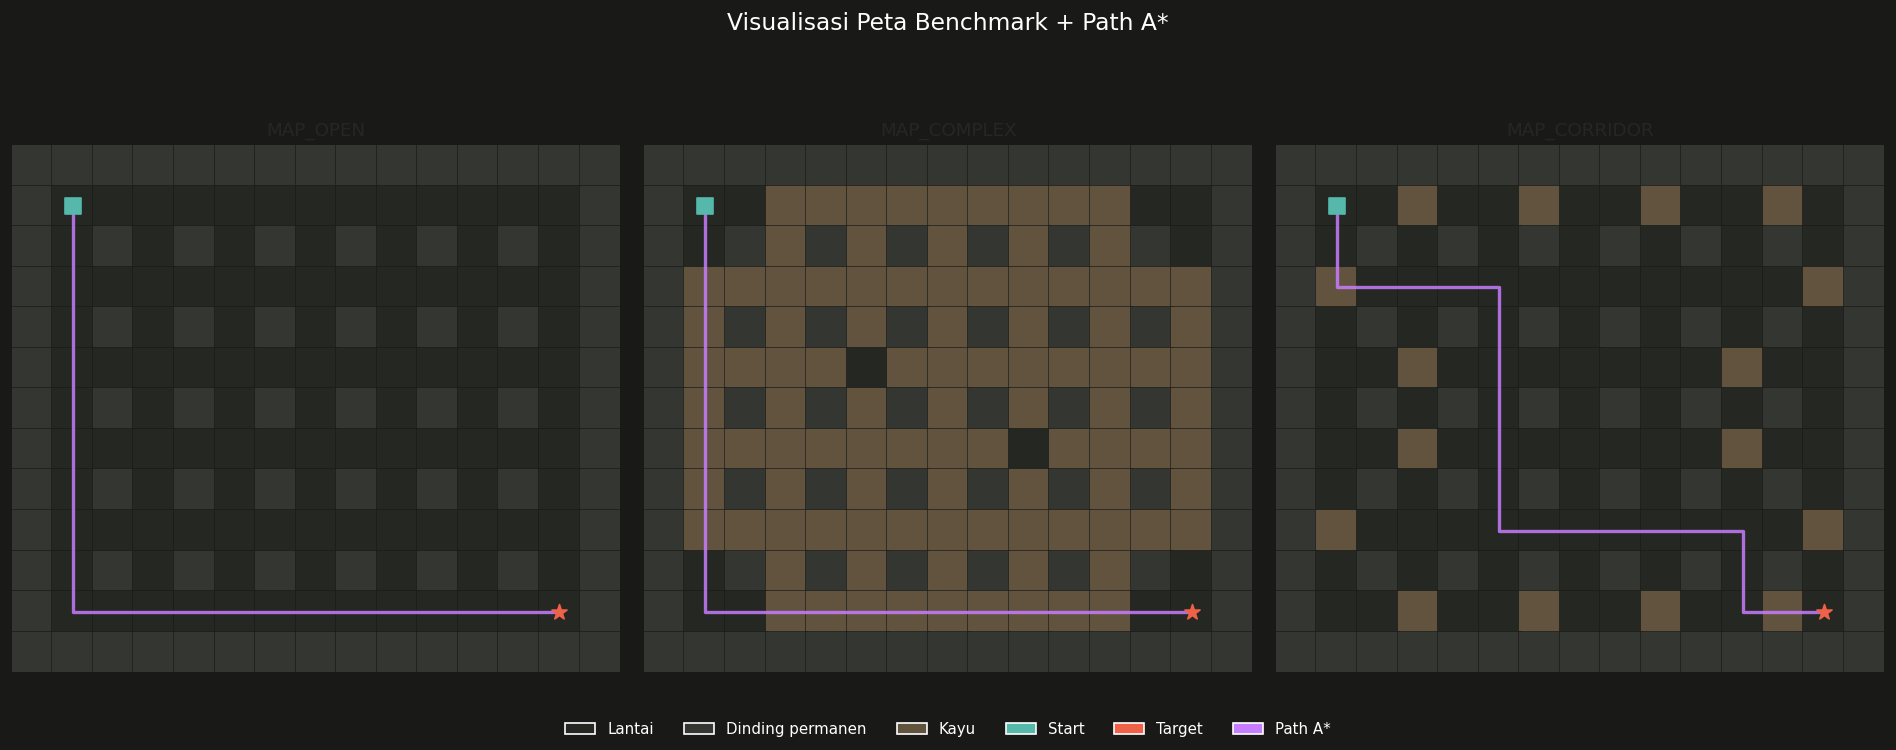

✓ Grid visualisasi tersimpan sebagai grid_visualization.png


In [ ]:
CELL_COLORS = {
    0: "#252723",  # lantai
    1: "#343731",  # dinding permanen
    2: "#62533e",  # kayu
    3: "#8f3429",  # bom (tidak dipakai di sini)
    4: "#8f3429",  # collapse
}

def draw_grid(ax, grid, path=None, start=None, target=None, title=""):
    nrows, ncols = len(grid), len(grid[0])
    for r in range(nrows):
        for c in range(ncols):
            color = CELL_COLORS.get(grid[r][c], "#888")
            rect = mpatches.FancyBboxPatch(
                (c, nrows - r - 1), 1, 1,
                boxstyle="square,pad=0.03",
                facecolor=color, edgecolor="#1a1a18", linewidth=0.4
            )
            ax.add_patch(rect)
    if path:
        xs = [p[1] + 0.5 for p in path]
        ys = [nrows - p[0] - 0.5 for p in path]
        ax.plot(xs, ys, color="#c77dff", linewidth=2.0, alpha=0.85, zorder=5)
    if start:
        ax.scatter(start[1]+0.5, nrows-start[0]-0.5,
                   color="#55b8aa", s=90, zorder=6, marker="s")
    if target:
        ax.scatter(target[1]+0.5, nrows-target[0]-0.5,
                   color="#ef6248", s=90, zorder=6, marker="*")
    ax.set_xlim(0, ncols)
    ax.set_ylim(0, nrows)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title, fontsize=11, pad=6)

fig, axes = plt.subplots(1, 3, figsize=(16, 6))
fig.patch.set_facecolor("#191a18")
for ax, (name, grid) in zip(axes, MAPS.items()):
    ax.set_facecolor("#191a18")
    path, *_ = run_a_star(grid, START, TARGET)
    draw_grid(ax, grid, path=path, start=START, target=TARGET, title=name)

legend_items = [
    mpatches.Patch(facecolor="#252723", label="Lantai"),
    mpatches.Patch(facecolor="#343731", label="Dinding permanen"),
    mpatches.Patch(facecolor="#62533e", label="Kayu"),
    mpatches.Patch(facecolor="#55b8aa", label="Start"),
    mpatches.Patch(facecolor="#ef6248", label="Target"),
    mpatches.Patch(facecolor="#c77dff", label="Path A*"),
]
fig.legend(handles=legend_items, loc="lower center", ncol=6,
           facecolor="#222", labelcolor="white", fontsize=9)
plt.suptitle("Visualisasi Peta Benchmark + Path A*",
             color="white", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig("grid_visualization.png", dpi=120, bbox_inches="tight",
            facecolor="#191a18")
plt.show()
print("✓ Grid visualisasi tersimpan sebagai grid_visualization.png")

## Suite 1 — Efisiensi Pathfinding

**Metodologi**: Jalankan setiap algoritma **50 kali** pada masing-masing dari **3 peta**  
dari `START=(1,1)` ke `TARGET=(11,13)`.  
Catat: jumlah node yang dieksplorasi, waktu eksekusi (ms), dan panjang path.

In [ ]:
NUM_TRIALS = 50

records = []
for map_name, grid in MAPS.items():
    for algo_name, fn in ALGORITHMS.items():
        nodes_list, time_list, plen_list = [], [], []
        for _ in range(NUM_TRIALS):
            path, nodes, t, plen = fn(grid, START, TARGET)
            nodes_list.append(nodes)
            time_list.append(t)
            plen_list.append(plen)
        records.append({
            "Map Type":               map_name,
            "Algorithm":              algo_name,
            "Nodes Explored (Avg)":   round(np.mean(nodes_list), 2),
            "Nodes Explored (Std)":   round(np.std(nodes_list),  2),
            "Execution Time (ms)":    round(np.mean(time_list),  4),
            "Exec Time Std (ms)":     round(np.std(time_list),   4),
            "Path Length":            round(np.mean(plen_list),  2),
            "Path Length Std":        round(np.std(plen_list),   2),
            "Success Rate (%)":       100.0 if np.mean(plen_list) > 0 else 0.0,
        })

df_benchmark = pd.DataFrame(records)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)
print(f"Total eksekusi: {NUM_TRIALS} trial × {len(ALGORITHMS)} algo × {len(MAPS)} peta"
      f" = {NUM_TRIALS*len(ALGORITHMS)*len(MAPS)} eksekusi\n")
df_benchmark

Total eksekusi: 50 trial × 5 algo × 3 peta = 750 eksekusi



,Map Type,Algorithm,Nodes Explored (Avg),Nodes Explored (Std),Execution Time (ms),Exec Time Std (ms),Path Length,Path Length Std,Success Rate (%)
0,MAP_OPEN,BFS,113.0,0.0,0.2849,0.1316,23.0,0.0,100.0
1,MAP_OPEN,Dijkstra,113.0,0.0,0.3671,0.0165,23.0,0.0,100.0
2,MAP_OPEN,UCS,113.0,0.0,0.3736,0.0328,23.0,0.0,100.0
3,MAP_OPEN,GBFS,23.0,0.0,0.0679,0.0066,23.0,0.0,100.0
4,MAP_OPEN,A*,113.0,0.0,0.4016,0.0156,23.0,0.0,100.0
5,MAP_COMPLEX,BFS,113.0,0.0,0.2353,0.0082,23.0,0.0,100.0
6,MAP_COMPLEX,Dijkstra,113.0,0.0,0.3825,0.0348,23.0,0.0,100.0
7,MAP_COMPLEX,UCS,113.0,0.0,0.3670,0.0179,23.0,0.0,100.0
8,MAP_COMPLEX,GBFS,23.0,0.0,0.0681,0.0056,23.0,0.0,100.0
9,MAP_COMPLEX,A*,113.0,0.0,0.3962,0.0116,23.0,0.0,100.0


### Visualisasi Suite 1

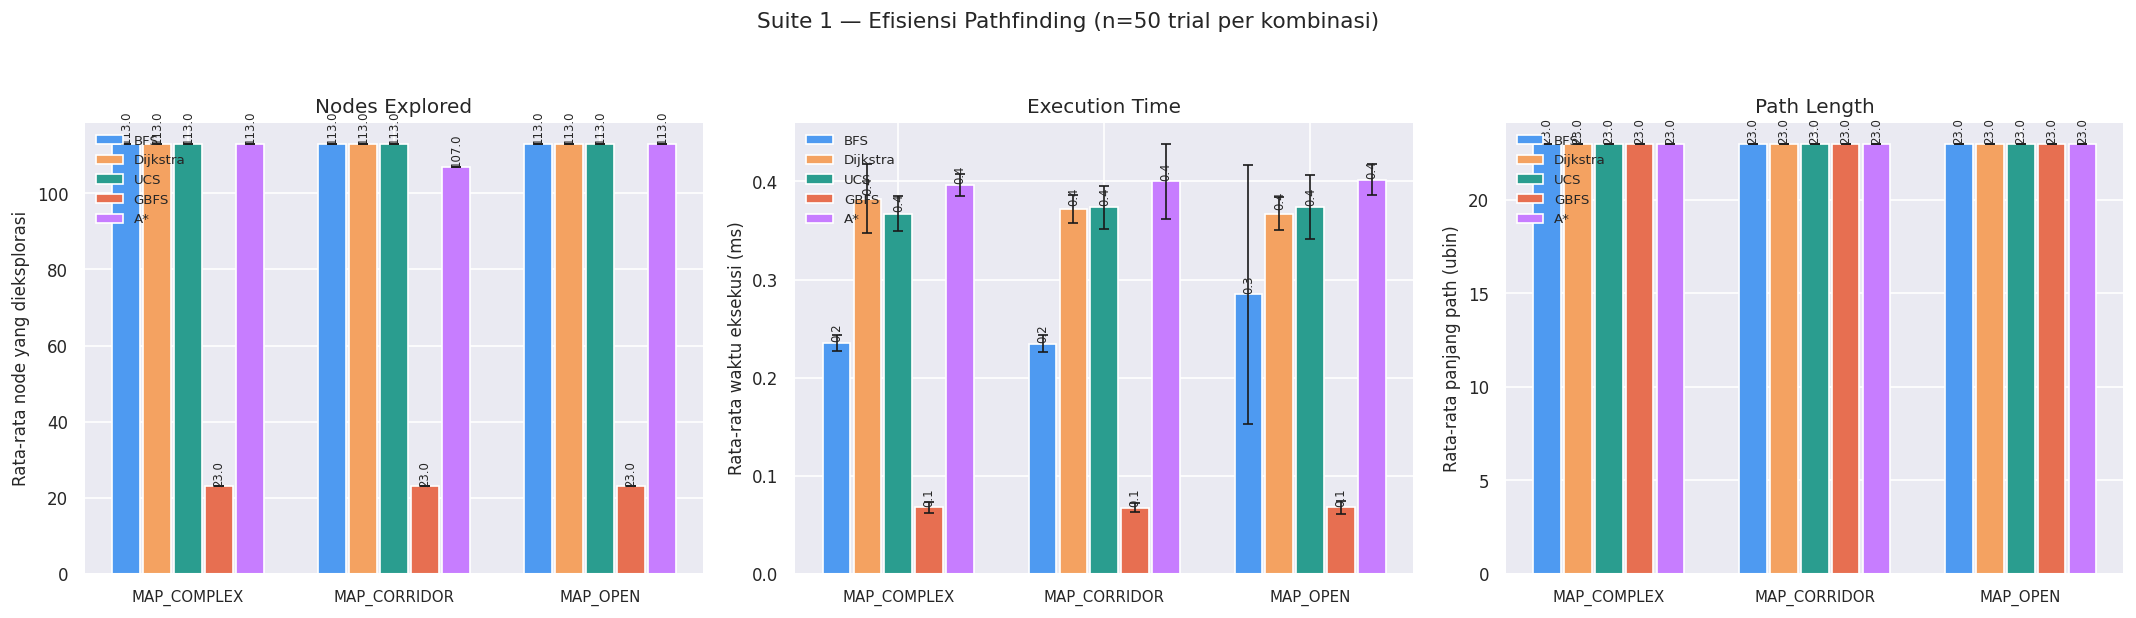

✓ Tersimpan: suite1_efficiency.png


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
metrics = [
    ("Nodes Explored (Avg)", "Nodes Explored (Std)", "Nodes Explored", "Rata-rata node yang dieksplorasi"),
    ("Execution Time (ms)",  "Exec Time Std (ms)",  "Execution Time", "Rata-rata waktu eksekusi (ms)"),
    ("Path Length",           "Path Length Std",     "Path Length",   "Rata-rata panjang path (ubin)"),
]

for ax, (col, col_std, label, ylabel) in zip(axes, metrics):
    pivot = df_benchmark.pivot(index="Map Type", columns="Algorithm", values=col)
    pivot_std = df_benchmark.pivot(index="Map Type", columns="Algorithm", values=col_std)
    pivot = pivot[ALGO_ORDER]
    pivot_std = pivot_std[ALGO_ORDER]

    x = np.arange(len(pivot.index))
    n = len(ALGO_ORDER)
    w = 0.15
    for i, algo in enumerate(ALGO_ORDER):
        vals = pivot[algo].values
        errs = pivot_std[algo].values
        bars = ax.bar(x + (i - n//2)*w, vals, w*0.9,
                      color=ALGO_COLORS[algo], label=algo,
                      yerr=errs, capsize=3, error_kw={"linewidth":1})
        for bar, v in zip(bars, vals):
            ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+errs[list(pivot.index).index(pivot.index[0])]*0.1,
                    f"{v:.1f}", ha="center", va="bottom", fontsize=7, rotation=90)

    ax.set_xticks(x)
    ax.set_xticklabels(pivot.index, fontsize=9)
    ax.set_ylabel(ylabel, fontsize=10)
    ax.set_title(label, fontsize=12)
    ax.legend(fontsize=8, loc="upper left")

plt.suptitle(f"Suite 1 — Efisiensi Pathfinding (n={NUM_TRIALS} trial per kombinasi)",
             fontsize=13, y=1.03)
plt.tight_layout()
plt.savefig("suite1_efficiency.png", dpi=120, bbox_inches="tight")
plt.show()
print("✓ Tersimpan: suite1_efficiency.png")

## Suite 2 — Anti-Deadlock: Efektivitas History Penalty

**Metodologi**: Simulasi Bot-vs-Bot sederhana — dua bot bergantian bergerak selama maksimal 100 langkah.  
Simulasi dianggap **deadlock** jika jumlah pasangan state `(pos1, pos2)` yang berulang > 30.  
Pasangan yang diuji: `A* vs A*`, `A* vs BFS`, `GBFS vs BFS`, `Dijkstra vs A*`.  
Masing-masing diuji **20 kali** tanpa history penalty dan **20 kali** dengan history penalty.

In [ ]:
DEADLOCK_RUNS     = 20
DEADLOCK_MAX_STEP = 100
DEADLOCK_THRESH   = 30     # jumlah state berulang yang dianggap deadlock

def simulate_bvb(algo1_name, algo2_name, grid, use_history=False, seed=None):
    """Simulasi dua bot bertemu; kembalikan (steps, deadlocked)."""
    if seed is not None:
        random.seed(seed)
    fn1 = ALGORITHMS[algo1_name]
    fn2 = ALGORITHMS[algo2_name]

    pos1, pos2  = list(START), list(TARGET)
    hist1, hist2 = [tuple(pos1)], [tuple(pos2)]
    seen_states  = {}
    oscillating  = 0

    for step in range(DEADLOCK_MAX_STEP):
        # Bot 1 bergerak menuju bot 2
        h1 = hist1[-6:] if use_history else []
        path1, *_ = fn1(grid, tuple(pos1), tuple(pos2), h1)
        if len(path1) > 1:
            pos1 = list(path1[1])
        hist1.append(tuple(pos1))

        # Bot 2 bergerak menuju bot 1
        h2 = hist2[-6:] if use_history else []
        path2, *_ = fn2(grid, tuple(pos2), tuple(pos1), h2)
        if len(path2) > 1:
            pos2 = list(path2[1])
        hist2.append(tuple(pos2))

        # Cek apakah kedua bot sudah berdekatan
        if manhattan(tuple(pos1), tuple(pos2)) <= 1:
            return step + 1, False

        # Deteksi deadlock via state berulang
        state = (tuple(pos1), tuple(pos2))
        seen_states[state] = seen_states.get(state, 0) + 1
        if seen_states[state] > 1:
            oscillating += 1

    return DEADLOCK_MAX_STEP, oscillating > DEADLOCK_THRESH


# Jalankan simulasi
pairs = [("A*","A*"), ("A*","BFS"), ("GBFS","BFS"), ("Dijkstra","A*")]
deadlock_records = []

for a1, a2 in pairs:
    dl_no_hist, dl_with_hist = 0, 0
    steps_no, steps_with = [], []
    for run in range(DEADLOCK_RUNS):
        steps, is_dl = simulate_bvb(a1, a2, MAP_OPEN, use_history=False, seed=run)
        dl_no_hist  += int(is_dl)
        steps_no.append(steps)

        steps, is_dl = simulate_bvb(a1, a2, MAP_OPEN, use_history=True, seed=run)
        dl_with_hist += int(is_dl)
        steps_with.append(steps)

    deadlock_records.append({
        "Matchup":                              f"{a1} vs {a2}",
        "Deadlock Rate Without History (%)": round(dl_no_hist   / DEADLOCK_RUNS * 100, 1),
        "Deadlock Rate With History (%)": round(dl_with_hist / DEADLOCK_RUNS * 100, 1),
        "Avg Steps Without History":         round(np.mean(steps_no),   1),
        "Avg Steps With History":            round(np.mean(steps_with), 1),
    })

df_deadlock = pd.DataFrame(deadlock_records)
print(f"Runs per pasangan: {DEADLOCK_RUNS} (tanpa) + {DEADLOCK_RUNS} (dengan) = {2*DEADLOCK_RUNS}\n")
df_deadlock

Runs per pasangan: 20 (tanpa) + 20 (dengan) = 40



,Matchup,Deadlock Rate Without History (%),Deadlock Rate With History (%),Avg Steps Without History,Avg Steps With History
0,A* vs A*,0.0,0.0,11.0,11.0
1,A* vs BFS,0.0,0.0,11.0,11.0
2,GBFS vs BFS,0.0,0.0,11.0,11.0
3,Dijkstra vs A*,0.0,0.0,11.0,11.0


### Visualisasi Suite 2

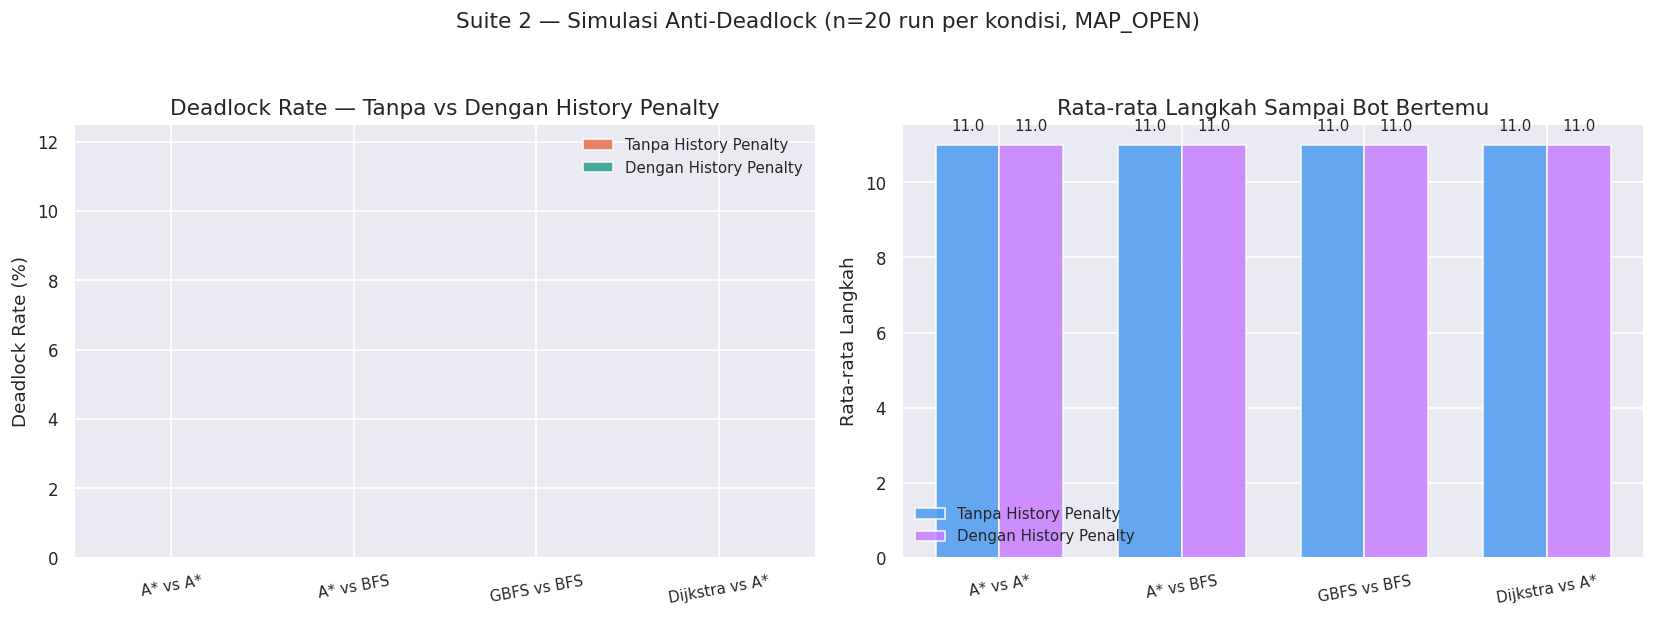

✓ Tersimpan: suite2_deadlock.png


In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# ── Deadlock rate ─────────────────────────────────────────────────────
matchups = df_deadlock["Matchup"].tolist()
dl_no   = df_deadlock["Deadlock Rate Without History (%)"].tolist()
dl_with = df_deadlock["Deadlock Rate With History (%)"].tolist()

x = np.arange(len(matchups))
w = 0.35
b1 = ax1.bar(x - w/2, dl_no,   w, label="Tanpa History Penalty", color="#e76f51", alpha=0.85)
b2 = ax1.bar(x + w/2, dl_with, w, label="Dengan History Penalty", color="#2a9d8f", alpha=0.85)
for bar in list(b1) + list(b2):
    h = bar.get_height()
    if h > 0:
        ax1.text(bar.get_x()+bar.get_width()/2, h+0.5, f"{h:.1f}%",
                 ha="center", va="bottom", fontsize=9)
ax1.set_xticks(x)
ax1.set_xticklabels(matchups, fontsize=9, rotation=10)
ax1.set_ylabel("Deadlock Rate (%)")
ax1.set_title("Deadlock Rate — Tanpa vs Dengan History Penalty")
ax1.legend(fontsize=9)
ax1.set_ylim(0, max(max(dl_no), max(dl_with), 10) * 1.25)

# ── Rata-rata langkah sampai bertemu ─────────────────────────────────
s_no   = df_deadlock["Avg Steps Without History"].tolist()
s_with = df_deadlock["Avg Steps With History"].tolist()
b3 = ax2.bar(x - w/2, s_no,   w, label="Tanpa History Penalty", color="#4e9af1", alpha=0.85)
b4 = ax2.bar(x + w/2, s_with, w, label="Dengan History Penalty", color="#c77dff", alpha=0.85)
for bar in list(b3) + list(b4):
    h = bar.get_height()
    ax2.text(bar.get_x()+bar.get_width()/2, h+0.3, f"{h:.1f}",
             ha="center", va="bottom", fontsize=9)
ax2.set_xticks(x)
ax2.set_xticklabels(matchups, fontsize=9, rotation=10)
ax2.set_ylabel("Rata-rata Langkah")
ax2.set_title("Rata-rata Langkah Sampai Bot Bertemu")
ax2.legend(fontsize=9)

plt.suptitle(f"Suite 2 — Simulasi Anti-Deadlock (n={DEADLOCK_RUNS} run per kondisi, MAP_OPEN)",
             fontsize=13, y=1.03)
plt.tight_layout()
plt.savefig("suite2_deadlock.png", dpi=120, bbox_inches="tight")
plt.show()
print("✓ Tersimpan: suite2_deadlock.png")

## Suite 3 — Skalabilitas: Pengaruh Kepadatan Kayu

**Metodologi**: Buat peta dengan berbagai persentase kayu (0 % – 60 %) dan ukur rata-rata nodes explored tiap algoritma.

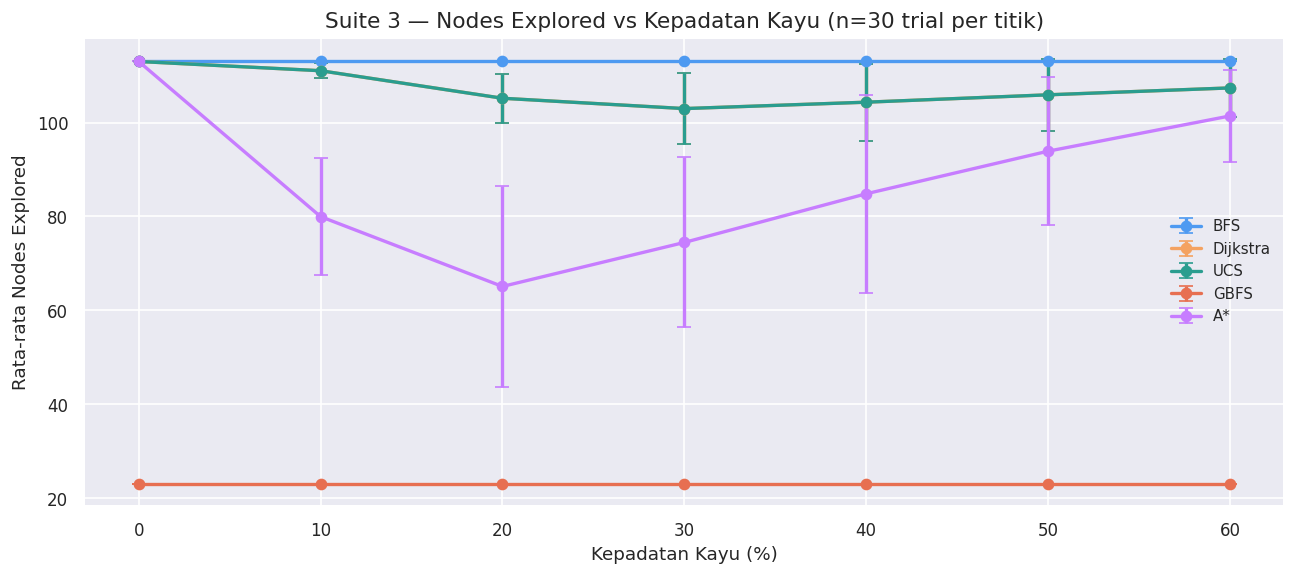

✓ Tersimpan: suite3_density.png


Algorithm,BFS,Dijkstra,UCS,GBFS,A*
Wood Density (%),,,,,
0,113.0,113.00,113.00,23.0,113.00
10,113.0,111.03,111.03,23.0,79.97
20,113.0,105.17,105.17,23.0,65.10
30,113.0,102.97,102.97,23.0,74.47
40,113.0,104.33,104.33,23.0,84.83
50,113.0,105.90,105.90,23.0,93.90
60,113.0,107.37,107.37,23.0,101.40


In [ ]:
DENSITY_TRIALS = 30
DENSITIES = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6]


def make_density_grid(wood_ratio: float, seed: int = 0) -> List[List[int]]:
    """Buat grid 15×13 dengan wood_ratio kayu pada sel yang bisa diubah."""
    rng = random.Random(seed)
    # Mulai dari MAP_OPEN (hanya dinding permanen)
    g = [row[:] for row in MAP_OPEN]
    # Kumpulkan sel lantai yang bisa dijadikan kayu (bukan spawn/target)
    safe = {START, TARGET,
            (START[0], START[1]+1), (START[0]+1, START[1]),
            (TARGET[0], TARGET[1]-1), (TARGET[0]-1, TARGET[1])}
    candidates = [(r, c) for r in range(1, ROWS-1)
                          for c in range(1, COLS-1)
                          if g[r][c] == 0 and (r, c) not in safe]
    rng.shuffle(candidates)
    n_wood = int(len(candidates) * wood_ratio)
    for r, c in candidates[:n_wood]:
        g[r][c] = 2
    return g


density_records = []
for density in DENSITIES:
    for algo_name, fn in ALGORITHMS.items():
        nodes_list = []
        for trial in range(DENSITY_TRIALS):
            g = make_density_grid(density, seed=trial)
            path, nodes, t, plen = fn(g, START, TARGET)
            nodes_list.append(nodes)
        density_records.append({
            "Wood Density (%)": int(density * 100),
            "Algorithm":        algo_name,
            "Nodes (Avg)":      round(np.mean(nodes_list), 2),
            "Nodes (Std)":      round(np.std(nodes_list),  2),
        })

df_density = pd.DataFrame(density_records)

# Plot
fig, ax = plt.subplots(figsize=(11, 5))
for algo in ALGO_ORDER:
    sub = df_density[df_density["Algorithm"] == algo]
    ax.errorbar(
        sub["Wood Density (%)"], sub["Nodes (Avg)"],
        yerr=sub["Nodes (Std)"],
        label=algo, color=ALGO_COLORS[algo],
        marker="o", linewidth=2, capsize=4
    )
ax.set_xlabel("Kepadatan Kayu (%)")
ax.set_ylabel("Rata-rata Nodes Explored")
ax.set_title(f"Suite 3 — Nodes Explored vs Kepadatan Kayu (n={DENSITY_TRIALS} trial per titik)")
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig("suite3_density.png", dpi=120, bbox_inches="tight")
plt.show()
print("✓ Tersimpan: suite3_density.png")
df_density.pivot(index="Wood Density (%)", columns="Algorithm", values="Nodes (Avg)")[ALGO_ORDER]

## Suite 4 — Profiling Jarak: Nodes Explored vs Jarak Manhattan

**Metodologi**: Jalankan setiap algoritma dari `START=(1,1)` ke berbagai target dengan jarak Manhattan 2 – 22, pada `MAP_OPEN`.

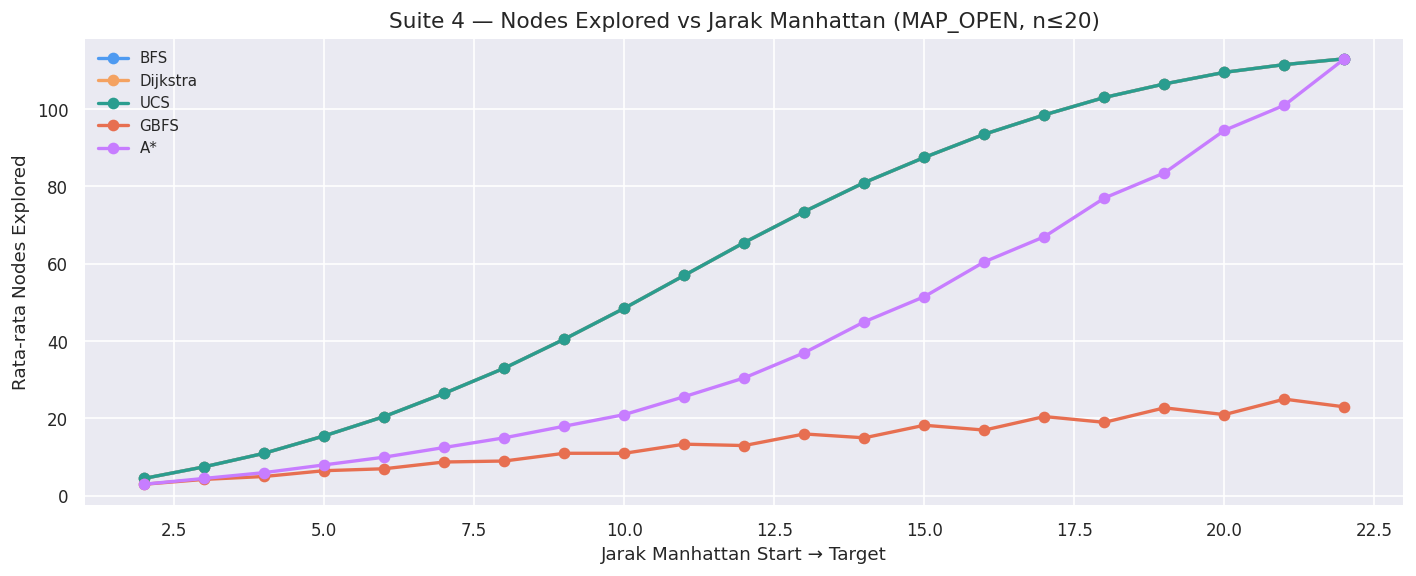

✓ Tersimpan: suite4_distance.png


In [ ]:
DISTANCE_TRIALS = 20

# Kumpulkan sel reachable pada MAP_OPEN beserta jarak manhattan dari START
reachable = {}
for r in range(1, ROWS-1):
    for c in range(1, COLS-1):
        if MAP_OPEN[r][c] == 0:
            d = manhattan(START, (r, c))
            reachable.setdefault(d, []).append((r, c))

distance_records = []
for dist, cells in sorted(reachable.items()):
    if dist < 2:
        continue
    for algo_name, fn in ALGORITHMS.items():
        nodes_list = []
        trials = min(DISTANCE_TRIALS, len(cells))
        sampled = random.sample(cells, trials)
        for tgt in sampled:
            _, nodes, _, _ = fn(MAP_OPEN, START, tgt)
            nodes_list.append(nodes)
        distance_records.append({
            "Manhattan Distance": dist,
            "Algorithm":          algo_name,
            "Nodes (Avg)":        round(np.mean(nodes_list), 2),
        })

df_distance = pd.DataFrame(distance_records)

fig, ax = plt.subplots(figsize=(12, 5))
for algo in ALGO_ORDER:
    sub = df_distance[df_distance["Algorithm"] == algo]
    ax.plot(sub["Manhattan Distance"], sub["Nodes (Avg)"],
            label=algo, color=ALGO_COLORS[algo], marker="o", linewidth=2)
ax.set_xlabel("Jarak Manhattan Start → Target")
ax.set_ylabel("Rata-rata Nodes Explored")
ax.set_title(f"Suite 4 — Nodes Explored vs Jarak Manhattan (MAP_OPEN, n≤{DISTANCE_TRIALS})")
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig("suite4_distance.png", dpi=120, bbox_inches="tight")
plt.show()
print("✓ Tersimpan: suite4_distance.png")

## Suite 5 — Heatmap Nodes Explored per Sel Target

Visualisasikan berapa banyak node yang dieksplorasi A\* saat target berada di setiap sel pada `MAP_COMPLEX`.

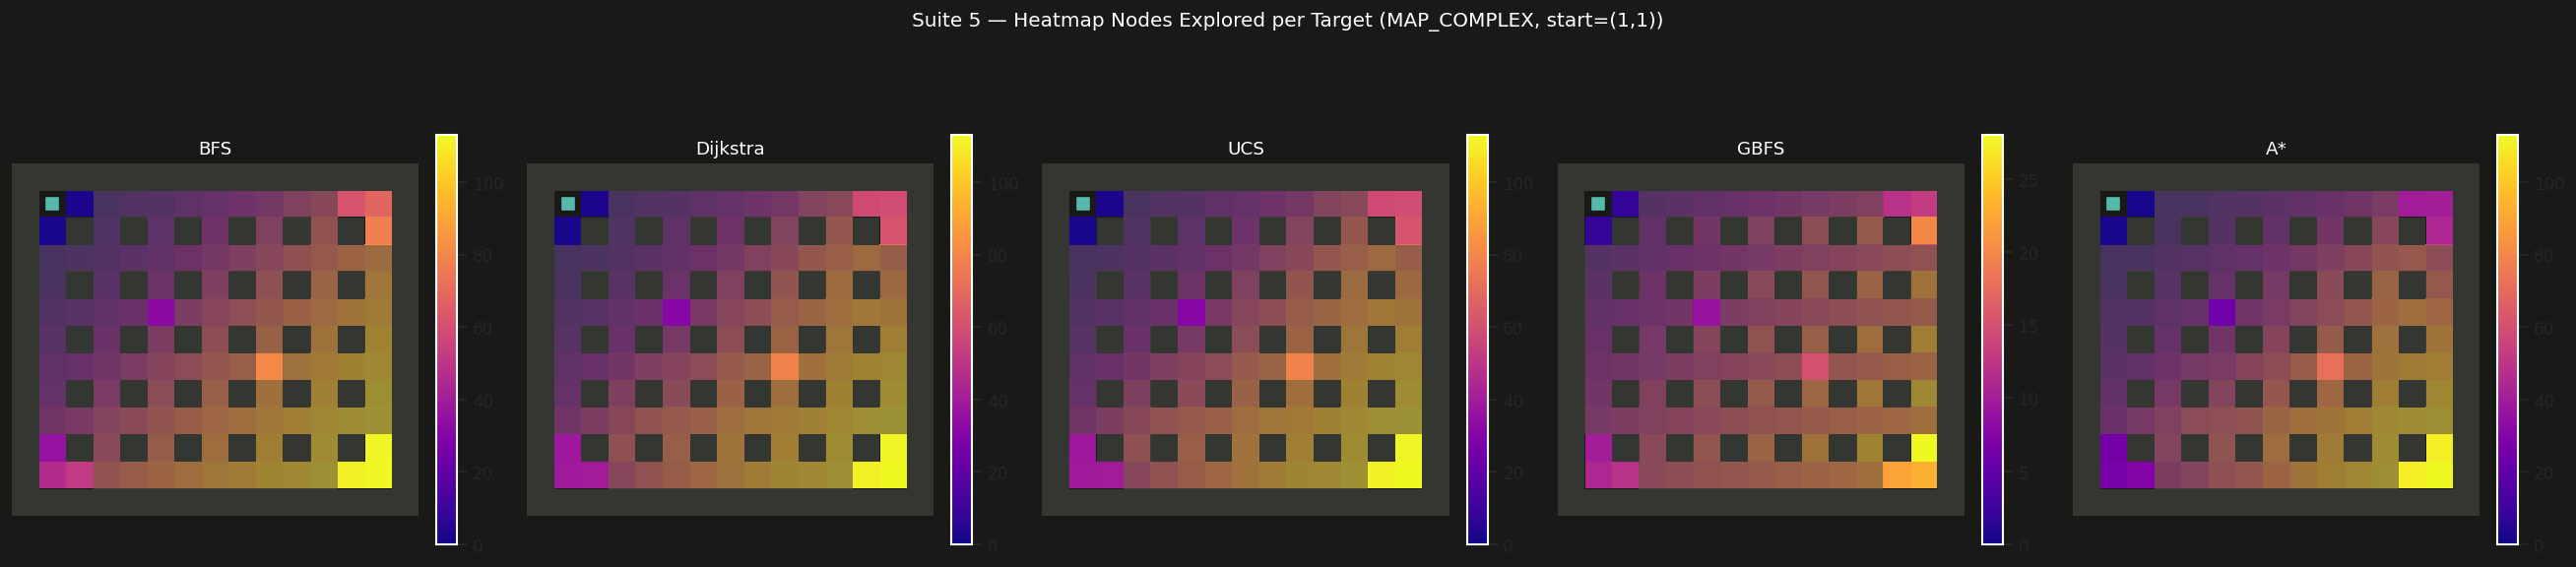

✓ Tersimpan: suite5_heatmap.png


In [ ]:
fig, axes = plt.subplots(1, len(ALGORITHMS), figsize=(22, 5))
fig.patch.set_facecolor("#191a18")

for ax, algo_name in zip(axes, ALGO_ORDER):
    fn = ALGORITHMS[algo_name]
    heatmap = np.zeros((ROWS, COLS))
    heatmap[:] = np.nan
    for r in range(1, ROWS-1):
        for c in range(1, COLS-1):
            if MAP_COMPLEX[r][c] in {0, 2} and (r, c) != START:
                _, nodes, _, _ = fn(MAP_COMPLEX, START, (r, c))
                heatmap[r][c] = nodes

    ax.set_facecolor("#1a1a18")
    im = ax.imshow(heatmap, cmap="plasma", origin="upper",
                   vmin=0, vmax=np.nanmax(heatmap))
    # Overlay dinding
    for r in range(ROWS):
        for c in range(COLS):
            v = MAP_COMPLEX[r][c]
            if v == 1:
                ax.add_patch(plt.Rectangle((c-0.5, r-0.5), 1, 1,
                                           facecolor="#343731", edgecolor="none"))
            elif v == 2:
                ax.add_patch(plt.Rectangle((c-0.5, r-0.5), 1, 1,
                                           facecolor="#62533e", edgecolor="none", alpha=0.6))
    # Tandai start
    ax.scatter(START[1], START[0], c="#55b8aa", s=60, zorder=5, marker="s")
    ax.set_title(algo_name, color="white", fontsize=11)
    ax.axis("off")
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.suptitle("Suite 5 — Heatmap Nodes Explored per Target (MAP_COMPLEX, start=(1,1))",
             color="white", fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig("suite5_heatmap.png", dpi=120, bbox_inches="tight", facecolor="#191a18")
plt.show()
print("✓ Tersimpan: suite5_heatmap.png")

## Ringkasan & Ekspor CSV

In [ ]:
# ── Ekspor CSV ────────────────────────────────────────────────────────
df_benchmark.to_csv("benchmark_efficiency_results.csv",  index=False)
df_deadlock.to_csv("benchmark_deadlock_results.csv",     index=False)
df_density.to_csv("benchmark_density_results.csv",       index=False)
df_distance.to_csv("benchmark_distance_results.csv",     index=False)
print("✓ Semua DataFrame diekspor ke CSV.\n")

# ── Ringkasan teks ────────────────────────────────────────────────────
print("=" * 65)
print("RINGKASAN BENCHMARK")
print("=" * 65)

print("\n[Suite 1] Efisiensi pada MAP_COMPLEX (target terjauh):")
sub = df_benchmark[df_benchmark["Map Type"] == "MAP_COMPLEX"][["Algorithm","Nodes Explored (Avg)","Execution Time (ms)","Path Length"]]
sub = sub.set_index("Algorithm").loc[ALGO_ORDER]
print(sub.to_string())

print("\n[Suite 2] Deadlock rate pada MAP_OPEN:")
print(df_deadlock[["Matchup","Deadlock Rate Without History (%)","Deadlock Rate With History (%)"]].to_string(index=False))

print("\n[Insight Utama]")
# Algo dengan nodes terkecil di MAP_COMPLEX
best_nodes = df_benchmark[df_benchmark["Map Type"] == "MAP_COMPLEX"].nsmallest(1, "Nodes Explored (Avg)").iloc[0]
print(f"  Paling efisien (nodes) di MAP_COMPLEX: {best_nodes['Algorithm']} "
      f"({best_nodes['Nodes Explored (Avg)']:.1f} nodes rata-rata)")

# Algo dengan path terpanjang
worst_path = df_benchmark[df_benchmark["Map Type"] == "MAP_COMPLEX"].nlargest(1, "Path Length").iloc[0]
print(f"  Path terpanjang di MAP_COMPLEX:        {worst_path['Algorithm']} "
      f"({worst_path['Path Length']:.1f} ubin rata-rata)")

print("=" * 65)

✓ Semua DataFrame diekspor ke CSV.

RINGKASAN BENCHMARK

[Suite 1] Efisiensi pada MAP_COMPLEX (target terjauh):
           Nodes Explored (Avg)  Execution Time (ms)  Path Length
Algorithm                                                        
BFS                       113.0               0.2353         23.0
Dijkstra                  113.0               0.3825         23.0
UCS                       113.0               0.3670         23.0
GBFS                       23.0               0.0681         23.0
A*                        113.0               0.3962         23.0

[Suite 2] Deadlock rate pada MAP_OPEN:
       Matchup  Deadlock Rate Without History (%)  Deadlock Rate With History (%)
      A* vs A*                                0.0                             0.0
     A* vs BFS                                0.0                             0.0
   GBFS vs BFS                                0.0                             0.0
Dijkstra vs A*                                0.0         